# Northern Beaches Water Quality — Exceedance Prediction (stratified random split)
ENGG2112 · AI for Good

**This notebook is a comparison.** Same pipeline as `Prediction-AI.ipynb`, but the data is split **randomly** (stratified by water-quality band) instead of by date. Comparing the two shows whether a random split gives a misleading picture.

**Goal:** predict whether the next Beachwatch sample at a site will exceed the enterococci guideline (poor = 1, safe = 0).

| Section | What happens |
|---|---|
| 0–1 | Imports and settings |
| 2 | **Data cleaning**: blank records, impossible values, duplicates, averaging repeats, sorting |
| 3–4 | Create the label (poor/safe) and quick checks |
| 5 | **Data merging**: attach rainfall from the nearest SILO point to every sample |
| 6 | Features (model inputs) |
| 7 | **Data splitting**: band each sample (good/medium/bad), stratified random 60/20/20, then site feature + fill blanks |
| 8–9 | Define and train the models, compare on validation |
| 10 | Final test-set results |
| 11 | Did using all sites help Narrabeen? |
| 12 | How to compare with the chronological notebook |

## 0. Imports

### 0.1 Load libraries
**What it does:** Loads the toolkits: pandas (tables), matplotlib (plots), scikit-learn (Logistic Regression, Random Forest, metrics) and XGBoost. If XGBoost is missing, run `pip install xgboost` (and `pip install openpyxl` for the rainfall .xlsx files).

**Output:** Nothing. An error here means a library isn't installed.

In [13]:
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

## 1. Settings

### 1.1 Config
**What it does:** All the settings in one place. Change things here, not further down.
- `SITES`: `'all'`, or a list of exact names from the `Swim site` column.
- `FOCUS_SITE`: the site Section 11 checks.
- `THRESHOLD`: poor = enterococci **≥** 41 CFU/100 mL. ⚠️ Check the comparator (≥ vs >) against the NHMRC/Beachwatch source and cite it.
- `BAND_EDGES` / `BAND_NAMES`: water-quality bands used to stratify the split. ⚠️ The 200 boundary is taken from the NHMRC microbial categories (40 / 200 / 500): verify against the source before citing.
- `TRAIN_FRAC` / `VAL_FRAC` / `TEST_FRAC`: split proportions (must add to 1).

**Output:** Nothing.

In [14]:
DATA_PATH = 'Water quality-Data.csv'
RAIN_FILES = sorted(glob.glob('* (*, *).xlsx'))   # 13 SILO files, 2000-01-01 → 2026-10-07

SITES = 'all'           # or e.g. ['Narrabeen Lagoon (Birdwood Park)', 'Bilarong Reserve']
FOCUS_SITE = 'Narrabeen Lagoon (Birdwood Park)'
THRESHOLD = 41

BAND_EDGES = [-np.inf, THRESHOLD, 201, np.inf]   # [0, 41) good | [41, 201) medium | 201+ bad
BAND_NAMES = ['good', 'medium', 'bad']

TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.6, 0.2, 0.2
RANDOM_STATE = 42   # fixes the random shuffle so results are repeatable

## 2. Data cleaning
Takes the raw Beachwatch CSV and turns it into one clean row per site per sampling day. Each check is its own cell so you can see what it removed or changed.

### 2.1 Load the raw data
**What it does:** Reads the Beachwatch CSV exactly as downloaded. `raw` is kept untouched so we can always compare against it.

**Output:** Number of rows and columns, then the first 5 rows.

In [15]:
raw = pd.read_csv(DATA_PATH, encoding='utf-8-sig')   # utf-8-sig strips the hidden BOM character on the first header
print('Raw data:', raw.shape[0], 'rows,', raw.shape[1], 'columns')
raw.head()

Raw data: 55507 rows, 9 columns


,Region,Council,Swim site,Date,Time,Enterococci (cfu/100mL),Water temperature (°C),Latitude,Longitude
0,Northern Sydney,Northern Beaches Council,Shelly Beach (Manly),21/9/2026,8:18:00,1.0,18.0,-33.800514,151.297668
1,Northern Sydney,Northern Beaches Council,Whale Beach,21/9/2026,9:27:00,0.0,18.0,-33.611207,151.332254
2,Northern Sydney,Northern Beaches Council,South Curl Curl Beach,21/9/2026,8:54:00,0.0,18.0,-33.773397,151.293337
3,Northern Sydney,Northern Beaches Council,Collaroy Beach,21/9/2026,9:49:00,0.0,19.0,-33.732619,151.302884
4,Northern Sydney,Northern Beaches Council,Avalon Beach,21/9/2026,9:14:00,0.0,18.0,-33.635658,151.332569


### 2.2 Rename columns, convert dates, keep useful columns
**What it does:** Gives columns short names, turns the date text (`21/9/2026`) into real dates, and keeps only the columns we use. Region, Council and Time are dropped (not used as features).

**Output:** Column names and their data types (`date` should be `datetime64`).

In [16]:
df = raw.rename(columns={
    'Swim site': 'site',
    'Enterococci (cfu/100mL)': 'entero',
    'Water temperature (°C)': 'water_temp',
})
df['date'] = pd.to_datetime(df['Date'], dayfirst=True)
df = df[['site', 'date', 'entero', 'water_temp', 'Latitude', 'Longitude']]
df.dtypes

site                     str
date          datetime64[us]
entero               float64
water_temp           float64
Latitude             float64
Longitude            float64
dtype: object

### 2.3 Select sites
**What it does:** Keeps only the sites listed in `SITES` (all of them by default).

**Output:** How many sites are in the file, and how many rows are kept.

In [17]:
print('Sites in file:', df['site'].nunique())
if SITES != 'all':
    df = df[df['site'].isin(SITES)]
df = df.copy()
print('Rows kept:', len(df), 'from', df['site'].nunique(), 'sites')

Sites in file: 42
Rows kept: 55507 from 42 sites


### 2.4 Blank records report
**What it does:** Counts the blank (missing) values in every column before we fix anything.

**Output:** A table of blank counts and % blank per column. Expect a few blank `entero` values and lots of blank `water_temp` (it wasn't recorded in early years).

In [18]:
pd.DataFrame({'blank records': df.isna().sum(),
              '% blank': (df.isna().mean() * 100).round(1)})

,blank records,% blank
site,0,0.0
date,0,0.0
entero,135,0.2
water_temp,23886,43.0
Latitude,0,0.0
Longitude,0,0.0


### 2.5 Remove rows with no enterococci result
**What it does:** A row without an enterococci result has no answer to learn from, so it's removed. Blank `water_temp` rows are **kept**: those get filled in Section 7.2.

**Output:** Rows before and after, and how many were removed.

In [19]:
before = len(df)
df = df.dropna(subset=['entero'])
print(f'Before: {before} | After: {len(df)} | Removed: {before - len(df)} rows with blank enterococci')

Before: 55507 | After: 55372 | Removed: 135 rows with blank enterococci


### 2.6 Fix impossible water temperatures
**What it does:** Some water temperatures are entry errors (e.g. 245 or 1616 °C, probably missing decimal points). Anything outside 5–35 °C is set to blank rather than guessed.

**Output:** How many values were blanked, and the remaining min/max (should be within 5–35).

In [20]:
bad = df['water_temp'].notna() & ~df['water_temp'].between(5, 35)
print('Impossible values found:', bad.sum(), '→', sorted(df.loc[bad, 'water_temp'].unique().tolist()))
df.loc[bad, 'water_temp'] = np.nan
print('Water temp range now:', df['water_temp'].min(), '→', df['water_temp'].max(), '°C')

Impossible values found: 12 → [2.0, 129.0, 156.0, 200.0, 217.0, 222.0, 227.0, 234.0, 242.0, 245.0, 1536.0, 1616.0]
Water temp range now: 9.0 → 29.0 °C


### 2.7 Duplicates and averaging repeat samples
**What it does:** Two kinds of duplicates:
1. **Exact copies** (same row entered twice) are deleted. Because Time was dropped in 2.2, same-day re-tests with identical results also count as copies here.
2. **Repeat samples** (same site and day, different results, e.g. a re-test in the afternoon) are **averaged** into one row, so each site has at most one sample per day.

**Output:** Number of exact copies removed, a table of the repeat samples, and the row count after averaging.

In [21]:
before = len(df)
df = df.drop_duplicates()
print('Exact duplicate rows removed:', before - len(df))

repeats = df.duplicated(['site', 'date'], keep=False)
print('Repeat samples (same site + day, different results):', repeats.sum())
display(df[repeats].sort_values(['site', 'date']))

df = (df.groupby(['site', 'date'], as_index=False)
        .agg(entero=('entero', 'mean'), water_temp=('water_temp', 'mean'),
             Latitude=('Latitude', 'first'), Longitude=('Longitude', 'first')))
print('Rows after averaging repeats:', len(df))

Exact duplicate rows removed: 9
Repeat samples (same site + day, different results): 4


,site,date,entero,water_temp,Latitude,Longitude
55303,Clontarf Pool,2000-02-01,460.0,NaN,-33.805790,151.251720
55304,Clontarf Pool,2000-02-01,16.0,NaN,-33.805790,151.251720
11426,South Scotland Island,2020-10-26,36.0,19.0,-33.644454,151.291354
11427,South Scotland Island,2020-10-26,36.0,18.0,-33.644454,151.291354


Rows after averaging repeats: 55361


### 2.8 Sort by site and date
**What it does:** Puts each site's samples in date order. Needed so 'previous sample' features in Section 6 really are the previous sample.

**Output:** The first 5 rows (one site, earliest dates first) and the final cleaned row count.

In [22]:
df = df.sort_values(['site', 'date']).reset_index(drop=True)
print('Clean data:', len(df), 'rows,', df['site'].nunique(), 'sites,',
      df['date'].min().date(), '→', df['date'].max().date())
df.head()

Clean data: 55361 rows, 42 sites, 2000-01-02 → 2026-09-21


,site,date,entero,water_temp,Latitude,Longitude
0,Avalon Beach,2000-01-04,0.0,NaN,-33.635658,151.332569
1,Avalon Beach,2000-01-11,6.0,NaN,-33.635658,151.332569
2,Avalon Beach,2000-01-16,12.0,NaN,-33.635658,151.332569
3,Avalon Beach,2000-01-22,90.0,NaN,-33.635658,151.332569
4,Avalon Beach,2000-01-28,6.0,NaN,-33.635658,151.332569


## 3. Target label

### 3.1 Create the poor/safe label
**What it does:** Adds the answer column `poor`: 1 if enterococci ≥ `THRESHOLD`, otherwise 0. This is what the models learn to predict.

**Output:** Samples and exceedance rate per site, highest first (lagoons/baths should be at the top).

In [23]:
df['poor'] = (df['entero'] >= THRESHOLD).astype(int)

(df.groupby('site')['poor'].agg(['count', 'mean'])
   .rename(columns={'count': 'samples', 'mean': 'exceed_rate'})
   .sort_values('exceed_rate', ascending=False).round(3))

,samples,exceed_rate
site,,
Bilarong Reserve,722,0.324
Narrabeen Lagoon (Birdwood Park),1230,0.287
Davidson Reserve,1223,0.246
Sangrado Baths,593,0.241
Bayview Baths,1213,0.228
Salt Pan Cove Baths,594,0.178
Gurney Crescent Baths,1224,0.164
Queenscliff Beach,1576,0.146
Winji Jimmi Bay,594,0.136


### 3.2 Class balance plot
**What it does:** Bar chart of safe vs poor samples.

**Output:** A bar chart. Poor is the minority class (~9% overall), which is why accuracy is misleading.

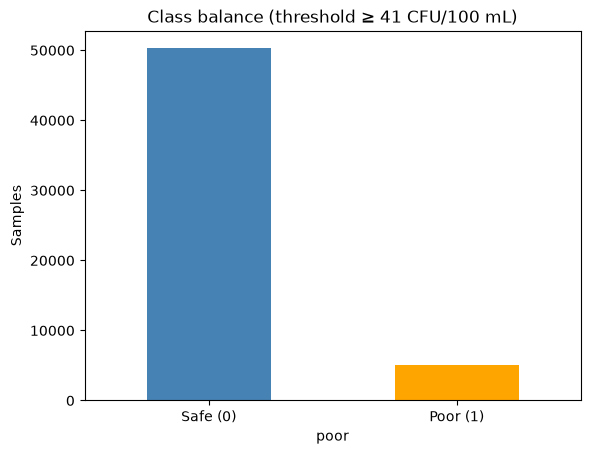

In [24]:
df['poor'].value_counts().sort_index().plot(kind='bar', color=['steelblue', 'orange'])
plt.xticks([0, 1], ['Safe (0)', 'Poor (1)'], rotation=0)
plt.ylabel('Samples')
plt.title(f'Class balance (threshold ≥ {THRESHOLD} CFU/100 mL)')
plt.show()

## 4. Quick checks

### 4.1 Sampling interval
**What it does:** Works out how many days apart each site's samples are.

**Output:** Summary stats of the gap in days (median should be ~6).

In [25]:
df.groupby('site')['date'].diff().dt.days.describe()

count    55319.000000
mean         6.878667
std          4.631884
min          1.000000
25%          6.000000
50%          6.000000
75%          7.000000
max        124.000000
Name: date, dtype: float64

### 4.2 Exceedance rate by year
**What it does:** Plots the share of poor samples each year.

**Output:** A line chart.

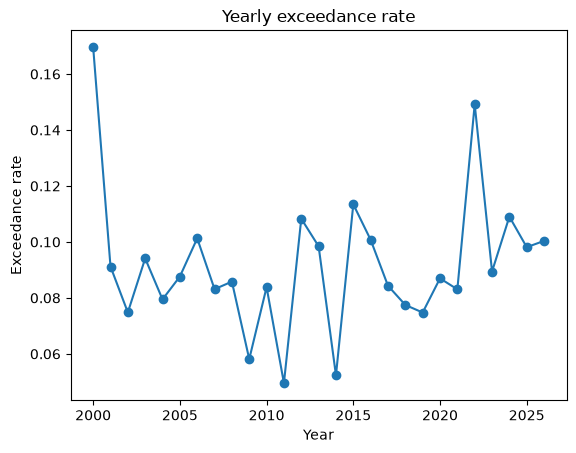

In [26]:
df.groupby(df['date'].dt.year)['poor'].mean().plot(marker='o')
plt.ylabel('Exceedance rate'); plt.xlabel('Year')
plt.title('Yearly exceedance rate')
plt.show()

## 5. Data merging: rainfall (SILO)
Daily rainfall from **SILO** (built from BOM observations, gap-free). 13 files:
- **11 grid points** ("Data Drill"): interpolated estimates on a 0.05° grid. The town name is just a label.
- **2 real stations** ("Patched Point"): Mona Vale Golf Club (66141) and Palm Beach Sunrise Rd (66128). Their true coordinates are read from inside the file (the file names are rounded).

⚠️ Cite SILO as the data source (CC BY 4.0 licence requires it). ⚠️ To verify: SILO daily rain for date D should be the 24h to **9am on D** (BOM convention). Confirm in SILO's documentation and cite it.

### 5.1 Load the rainfall files
**What it does:** Reads each SILO .xlsx: finds the coordinates in the notes at the top, then the daily table below. Keeps the daily rainfall (mm).

**Output:** How many rain points loaded (should be 13) and a table of each point's coordinates and date range.

In [27]:
def load_silo(path):
    """Read one SILO xlsx -> (lat, lon, daily rainfall Series indexed by date)."""
    raw_xl = pd.read_excel(path, header=None)

    # Coordinates are in the notes block, e.g. 'Lat, Long: -33.80 151.25' or 'Lat: -33.6795 Long: 151.3076'
    notes = ' '.join(str(v) for v in raw_xl[0].head(40))
    lat, lon = map(float, re.search(r'Lat(?:, Long)?:\s*(-?\d+\.\d+)\s*(?:Long:)?\s*(-?\d+\.\d+)', notes).groups())

    # Table starts at the 'Date' header row, then a units row, then data
    h = raw_xl.index[raw_xl[0].astype(str).str.strip() == 'Date'][0]
    d = raw_xl.iloc[h + 2:].copy()
    d.columns = raw_xl.iloc[h].astype(str).str.strip()
    d = d[pd.to_numeric(d['Date'], errors='coerce').notna()]
    d['date'] = pd.to_datetime(d['Date'].astype(int).astype(str), format='%Y%m%d')
    return lat, lon, d.set_index('date')['Rain'].astype(float)

points = {}
for f in RAIN_FILES:
    lat, lon, rain = load_silo(f)
    points[f.split(' (')[0]] = {'lat': lat, 'lon': lon, 'rain': rain}

print(len(points), 'rain points loaded')
pd.DataFrame({name: {'lat': p['lat'], 'lon': p['lon'], 'from': p['rain'].index.min().date(),
                     'to': p['rain'].index.max().date(), 'blank days': p['rain'].isna().sum()}
              for name, p in points.items()}).T

13 rain points loaded


,lat,lon,from,to,blank days
Balgowlah,-33.8,151.25,2000-01-01,2026-10-07,0
Beacon Hill,-33.75,151.25,2000-01-01,2026-10-07,0
Belrose,-33.75,151.2,2000-01-01,2026-10-07,0
Dee Why,-33.75,151.3,2000-01-01,2026-10-07,0
Duffys Forest,-33.65,151.2,2000-01-01,2026-10-07,0
Ingleside,-33.7,151.25,2000-01-01,2026-10-07,0
Manly,-33.8,151.3,2000-01-01,2026-10-07,0
Mona Vale,-33.6795,151.3076,2000-01-01,2026-10-07,0
Newport,-33.65,151.3,2000-01-01,2026-10-07,0
North Narrabeen,-33.7,151.3,2000-01-01,2026-10-07,0


### 5.2 Match each swim site to its nearest rain point
**What it does:** Measures the straight-line distance from each swim site to every rain point and picks the closest. Several sites can share one rain point.

**Output:** A table: site → rain point and distance in km (all should be within ~3.5 km).

In [28]:
def nearest_point(lat, lon):
    dist = {name: 111.2 * np.hypot(p['lat'] - lat, (p['lon'] - lon) * np.cos(np.radians(lat)))
            for name, p in points.items()}
    best = min(dist, key=dist.get)
    return best, dist[best]

site_xy = df.groupby('site')[['Latitude', 'Longitude']].first()
site_map = pd.DataFrame(
    [(site, *nearest_point(r['Latitude'], r['Longitude'])) for site, r in site_xy.iterrows()],
    columns=['site', 'rain_point', 'dist_km']).set_index('site')
site_map.sort_values('rain_point').round(1)

,rain_point,dist_km
site,,
Fairlight Beach,Balgowlah,2.3
Sangrado Baths,Balgowlah,1.1
Forty Baskets Pool,Balgowlah,1.9
Gurney Crescent Baths,Balgowlah,1.5
Clontarf Pool,Balgowlah,0.7
Davidson Reserve,Belrose,2.0
North Curl Curl Beach,Dee Why,2.0
Dee Why Beach,Dee Why,0.4
Collaroy Beach,Dee Why,2.0


### 5.3 Cumulative rainfall windows
**What it does:** For every rain point and every day, adds up the rain over the last 1, 2, 3 and 7 days (`rain_24h`, `rain_48h`, `rain_72h`, `rain_7d`). Free daily data can't give sub-daily windows.

**Output:** The first rows of the rainfall table. The first few days of 2000 show blanks in the longer windows (not enough history yet).

In [29]:
RAIN_COLS = ['rain_24h', 'rain_48h', 'rain_72h', 'rain_7d']

frames = []
for name, p in points.items():
    r = p['rain'].asfreq('D')   # one row per day so rolling windows are in days
    frames.append(pd.DataFrame({'rain_point': name, 'rain_24h': r,
                                'rain_48h': r.rolling(2).sum(),
                                'rain_72h': r.rolling(3).sum(),
                                'rain_7d': r.rolling(7).sum()}))
rain_feats = pd.concat(frames).rename_axis('date').reset_index()
rain_feats.head(8)

,date,rain_point,rain_24h,rain_48h,rain_72h,rain_7d
0,2000-01-01,Balgowlah,0.4,NaN,NaN,NaN
1,2000-01-02,Balgowlah,10.0,10.4,NaN,NaN
2,2000-01-03,Balgowlah,3.4,13.4,13.8,NaN
3,2000-01-04,Balgowlah,0.1,3.5,13.5,NaN
4,2000-01-05,Balgowlah,0.0,0.1,3.5,NaN
5,2000-01-06,Balgowlah,0.0,0.0,0.1,NaN
6,2000-01-07,Balgowlah,0.0,0.0,0.0,13.9
7,2000-01-08,Balgowlah,2.3,2.3,2.3,15.8


### 5.4 Merge rainfall into the water quality data
**What it does:** Adds each sample's site's rain point, then joins the rainfall windows on (rain point, date). Safe to re-run.

**Output:** Row count before/after (must be the same, a merge should never add or drop samples) and blank rainfall counts (only a few early-2000 samples).

In [30]:
before = len(df)
df = df.drop(columns=RAIN_COLS + ['rain_point'], errors='ignore')
df['rain_point'] = df['site'].map(site_map['rain_point'])
df = df.merge(rain_feats, on=['rain_point', 'date'], how='left')
print(f'Rows before merge: {before} | after merge: {len(df)}')
print('Blank rainfall values:')
print(df[RAIN_COLS].isna().sum())

Rows before merge: 55361 | after merge: 55361
Blank rainfall values:
rain_24h     0
rain_48h     0
rain_72h     8
rain_7d     39
dtype: int64


### 5.5 Check: does rain relate to poor water?
**What it does:** Groups samples by how much rain fell in the previous 72h and shows the exceedance rate in each band.

**Output:** A table. Exceedance should climb steeply as rainfall increases, a good sign rainfall is a useful input.

In [31]:
bands = pd.cut(df['rain_72h'], [-0.1, 0, 5, 20, 50, np.inf], labels=['0', '0-5', '5-20', '20-50', '50+'])
(df.groupby(bands, observed=True)['poor'].agg(['count', 'mean'])
   .rename(columns={'count': 'samples', 'mean': 'exceed_rate'}).round(3))

,samples,exceed_rate
rain_72h,,
0,15527,0.030
0-5,20257,0.046
5-20,11660,0.117
20-50,5312,0.227
50+,2597,0.438


## 6. Features (model inputs)
Only information known **before** the sample is taken (no leakage).

### 6.1 Sample history and season
**What it does:** For each sample, looks back at the **previous sample at the same site**: its result (log-scaled), whether it was poor, how many days ago it was, and its water temperature (same-day water temp is measured *at* sampling, so it isn't allowed). Also encodes the month as sin/cos so Dec and Jan count as close.

**Output:** Nothing printed (adds columns to `df`).

In [32]:
g = df.groupby('site')

df['prev_entero_log'] = np.log1p(g['entero'].shift(1))
df['prev_poor'] = g['poor'].shift(1)
df['days_since_prev'] = g['date'].diff().dt.days
df['prev_water_temp'] = g['water_temp'].shift(1)
df['month_sin'] = np.sin(2 * np.pi * df['date'].dt.month / 12)
df['month_cos'] = np.cos(2 * np.pi * df['date'].dt.month / 12)

### 6.2 Final feature list
**What it does:** Lists every input column the models will use, and removes each site's very first sample (it has no previous sample).

**Output:** Summary stats for each feature (`site_rate` is added after the split, in 7.3). `count` below the row total means that feature still has blanks (filled in 7.4).

In [33]:
FEATURES = [
    'prev_entero_log', 'prev_poor', 'days_since_prev', 'prev_water_temp',   # sample history
    'month_sin', 'month_cos',                                              # season
    'rain_24h', 'rain_48h', 'rain_72h', 'rain_7d',                         # rainfall
    'site_rate', 'Latitude', 'Longitude',                                  # site
]

df = df.dropna(subset=['prev_poor'])
print('Rows:', len(df))
df[[f for f in FEATURES if f != 'site_rate']].describe().round(2)

Rows: 55319


,prev_entero_log,prev_poor,days_since_prev,prev_water_temp,month_sin,month_cos,rain_24h,rain_48h,rain_72h,rain_7d,Latitude,Longitude
count,55319.00,55319.00,55319.00,31425.00,55319.00,55319.00,55319.00,55319.00,55319.00,55319.00,55319.00,55319.00
mean,1.42,0.09,6.88,19.80,0.03,0.05,3.07,6.66,9.84,22.87,-33.71,151.30
std,1.59,0.29,4.63,2.85,0.71,0.70,9.16,16.33,21.09,34.89,0.07,0.03
min,0.00,0.00,1.00,9.00,-1.00,-1.00,0.00,0.00,0.00,0.00,-33.81,151.20
25%,0.00,0.00,6.00,18.00,-0.50,-0.50,0.00,0.00,0.00,2.00,-33.79,151.29
50%,1.10,0.00,6.00,20.00,0.00,0.00,0.00,0.40,1.50,10.20,-33.70,151.30
75%,2.30,0.00,7.00,22.00,0.87,0.87,1.50,5.50,10.10,28.40,-33.64,151.31
max,11.49,1.00,124.00,29.00,1.00,1.00,171.20,199.40,299.30,417.50,-33.59,151.33


## 7. Data splitting: stratified random 60 / 20 / 20
1. Every sample gets a **band**: good (0–40), medium (41–200) or bad (over 200) CFU/100 mL.
2. Samples are **shuffled randomly**, but each split keeps the **same mix of bands** (stratified), so rare bad days are spread evenly.
- **Train (60%):** the models learn from this.
- **Validation (20%):** compare models and tune settings.
- **Test (20%):** used once at the end.

⚠️ **Why a random split can be optimistic:** samples days apart share the same storm, so the model can train on one sample from an event and be tested on another from the same event. It also trains on future years to predict past ones. The real tool can't do either. Check Section 12 to see whether that actually happened with our data. Either way, `Prediction-AI.ipynb` (split by date) is the realistic test and should give the headline results.

### 7.1 Label each sample's band
**What it does:** Puts every sample into good / medium / bad using `BAND_EDGES`. Bands are only used to stratify the split. The models still predict poor (≥ 41) vs safe.

**Output:** Number and % of samples in each band.

In [34]:
df['band'] = pd.cut(df['entero'], bins=BAND_EDGES, labels=BAND_NAMES, right=False)

pd.DataFrame({'samples': df['band'].value_counts().reindex(BAND_NAMES),
              '%': (df['band'].value_counts(normalize=True).reindex(BAND_NAMES) * 100).round(1)})

,samples,%
band,,
good,50221,90.8
medium,3690,6.7
bad,1408,2.5


### 7.2 Stratified random split
**What it does:** Two random cuts, both keeping the band mix: first sets aside `TEST_FRAC` as the test set, then splits the rest into train and validation. `RANDOM_STATE` makes the shuffle repeatable.

**Output:** A table per split: rows, % of data, poor rate, and the % of good / medium / bad. The band % should be almost identical across the three splits.

In [35]:
trval, test = train_test_split(df, test_size=TEST_FRAC, stratify=df['band'], random_state=RANDOM_STATE)
train, val = train_test_split(trval, test_size=VAL_FRAC / (1 - TEST_FRAC), stratify=trval['band'],
                              random_state=RANDOM_STATE)
train, val, test = train.copy(), val.copy(), test.copy()
splits = {'train': train, 'validation': val, 'test': test}

summary = pd.DataFrame({name: {'rows': len(d), '% of data': round(100 * len(d) / len(df), 1),
                               'poor rate': round(d['poor'].mean(), 3)}
                        for name, d in splits.items()}).T
band_mix = pd.DataFrame({name: (d['band'].value_counts(normalize=True).reindex(BAND_NAMES) * 100).round(1)
                         for name, d in splits.items()}).T.add_suffix(' %')
summary.join(band_mix)

,rows,% of data,poor rate,good %,medium %,bad %
train,33191.0,60.0,0.092,90.8,6.7,2.5
validation,11064.0,20.0,0.092,90.8,6.7,2.5
test,11064.0,20.0,0.092,90.8,6.7,2.5


### 7.3 Site feature (from training rows only)
**What it does:** `site_rate` = each site's average exceedance rate, worked out from the **training rows only**, so validation/test answers can't leak in. Tells one model that lagoons behave differently from open beaches.

**Output:** The 10 sites with the highest training exceedance rate.

In [36]:
train_rates = train.groupby('site')['poor'].mean()
for d in splits.values():
    d['site_rate'] = d['site'].map(train_rates).fillna(train['poor'].mean())
train_rates.sort_values(ascending=False).round(3).head(10)

site
Bilarong Reserve                    0.323
Narrabeen Lagoon (Birdwood Park)    0.295
Davidson Reserve                    0.266
Sangrado Baths                      0.242
Bayview Baths                       0.210
Salt Pan Cove Baths                 0.195
Gurney Crescent Baths               0.171
Queenscliff Beach                   0.140
Shelly Beach (Manly)                0.135
Winji Jimmi Bay                     0.123
Name: poor, dtype: float64

### 7.4 Fill remaining blanks with the training average
**What it does:** Some features still have blanks (mostly `prev_water_temp`, plus a few early rainfall windows). Each blank is filled with that feature's **median** (middle value) from the **training set only**, the same numbers for all three splits.

**Output:** Blank counts per split before filling, the median used for each feature, and a check that 0 blanks remain.

In [37]:
print('Blank values before filling:')
display(pd.DataFrame({name: d[FEATURES].isna().sum() for name, d in splits.items()}).query('train + validation + test > 0'))

train_medians = train[FEATURES].median()
for d in splits.values():
    d[FEATURES] = d[FEATURES].fillna(train_medians)

print('Medians used (from training data):')
display(train_medians.round(2).to_frame('median'))
print('Blank values remaining:', sum(d[FEATURES].isna().sum().sum() for d in splits.values()))

Blank values before filling:


,train,validation,test
prev_water_temp,14321,4760,4813


Medians used (from training data):


,median
prev_entero_log,1.10
prev_poor,0.00
days_since_prev,6.00
prev_water_temp,20.00
month_sin,0.00
month_cos,0.00
rain_24h,0.00
rain_48h,0.40
rain_72h,1.60
rain_7d,10.30


Blank values remaining: 0


### 7.5 Separate inputs (X) from answers (y)
**What it does:** `X` = the feature columns, `y` = the `poor` label, for each split.

**Output:** The shape (rows, columns) of each X.

In [38]:
X_train, y_train = train[FEATURES], train['poor']
X_val, y_val = val[FEATURES], val['poor']
X_test, y_test = test[FEATURES], test['poor']
print('X_train', X_train.shape, '| X_val', X_val.shape, '| X_test', X_test.shape)

X_train (33191, 13) | X_val (11064, 13) | X_test (11064, 13)


## 8. Define the models

### 8.1 Set up the three models
**What it does:** Creates the three untrained models. All give poor days extra weight so the rare class isn't ignored.
- **Logistic Regression** (scaled inputs): one weight per input, simple and interpretable.
- **Random Forest:** 300 decision trees that vote.
- **XGBoost:** trees built one after another, each fixing the last one's mistakes.

**Output:** Nothing.

In [39]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    'Logistic Regression': Pipeline([
        ('scale', StandardScaler()),
        ('clf', LogisticRegression(class_weight='balanced', max_iter=1000)),
    ]),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                            min_samples_leaf=5, random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                             scale_pos_weight=pos_weight, eval_metric='logloss',
                             random_state=RANDOM_STATE),
}

## 9. Train the models and compare on validation
Training = the model looks at the training rows (inputs + real answer) and adjusts itself to map one to the other.

### 9.1 Train on the training set, score on validation
**What it does:** Fits each model on train, then predicts the validation rows it hasn't seen. Comparing training F1 with validation F1 shows overfitting: a big gap means the model memorised the training data instead of learning general patterns.

**Output:** A table per model: training F1, and validation recall / precision / F1.

In [40]:
val_rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)
    val_rows.append({'model': name,
                     'train F1': f1_score(y_train, train_pred),
                     'val recall (poor)': recall_score(y_val, val_pred),
                     'val precision (poor)': precision_score(y_val, val_pred, zero_division=0),
                     'val F1 (poor)': f1_score(y_val, val_pred)})
val_results = pd.DataFrame(val_rows).set_index('model').round(3)
val_results

,train F1,val recall (poor),val precision (poor),val F1 (poor)
model,,,,
Logistic Regression,0.415,0.681,0.290,0.407
Random Forest,0.749,0.594,0.410,0.485
XGBoost,0.461,0.695,0.317,0.436


### 9.2 Pick the best model
**What it does:** Chooses the model with the highest validation F1. This is decided **before** looking at the test set.

**Output:** The name of the chosen model.

In [41]:
best = val_results['val F1 (poor)'].idxmax()
print('Best on validation:', best)

Best on validation: Random Forest


## 10. Final results on the test set (random 20%)

### 10.1 Retrain on train + validation
**What it does:** Now that the choices are made, each model is retrained on train + validation together (80% of the data).

**Output:** Nothing printed.

In [42]:
X_trval = pd.concat([X_train, X_val])
y_trval = pd.concat([y_train, y_val])

models['XGBoost'].set_params(scale_pos_weight=(y_trval == 0).sum() / (y_trval == 1).sum())
for model in models.values():
    model.fit(X_trval, y_trval)

### 10.2 Test-set scores
**What it does:** Each model predicts the test samples, compared with the real lab results. Primary metrics: **recall** (of the truly poor days, how many we caught) and **F1** (balance of recall and precision). Accuracy is for context only (inflated by the many safe ocean-beach days).

**Output:** A table of recall, precision, F1 and accuracy per model.

In [43]:
rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    rows.append({'model': name,
                 'recall (poor)': recall_score(y_test, pred),
                 'precision (poor)': precision_score(y_test, pred, zero_division=0),
                 'F1 (poor)': f1_score(y_test, pred),
                 'accuracy': accuracy_score(y_test, pred)})
results = pd.DataFrame(rows).set_index('model').round(3)
results

,recall (poor),precision (poor),F1 (poor),accuracy
model,,,,
Logistic Regression,0.701,0.281,0.401,0.807
Random Forest,0.644,0.425,0.512,0.887
XGBoost,0.721,0.308,0.431,0.825


### 10.3 Confusion matrices
**What it does:** For each model, counts the four outcomes: correct safe, false alarm, missed poor day, correct poor.

**Output:** Three 2×2 grids. Bottom-left = missed poor days (false negatives, the costly error).

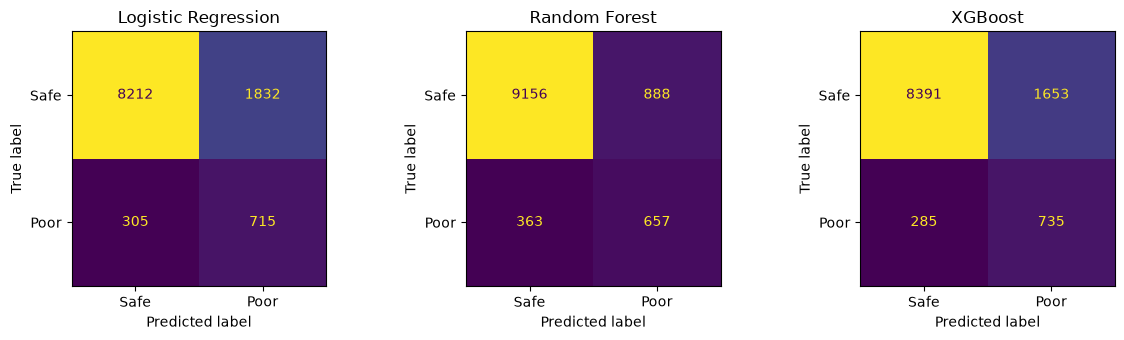

In [44]:
fig, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 3.5))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, model.predict(X_test)),
                           display_labels=['Safe', 'Poor']).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

### 10.4 Results per site
**What it does:** Breaks the best model's test results down by site, to see where it works well and where it struggles.

**Output:** A table per site: samples, poor days, recall and F1, sorted by number of poor days.

In [45]:
test_pred = test.assign(pred=models[best].predict(X_test))

site_rows = []
for site, s in test_pred.groupby('site'):
    site_rows.append({'site': site, 'samples': len(s), 'poor days': s['poor'].sum(),
                      'recall (poor)': recall_score(s['poor'], s['pred'], zero_division=0),
                      'F1 (poor)': f1_score(s['poor'], s['pred'], zero_division=0)})
print('Model:', best)
pd.DataFrame(site_rows).set_index('site').sort_values('poor days', ascending=False).round(3)

Model: Random Forest


,samples,poor days,recall (poor),F1 (poor)
site,,,,
Narrabeen Lagoon (Birdwood Park),273,80,0.862,0.559
Bayview Baths,245,58,0.759,0.540
South Steyne Beach,319,50,0.540,0.478
Bilarong Reserve,151,48,0.875,0.512
Queenscliff Beach,305,47,0.766,0.632
Davidson Reserve,256,46,0.870,0.702
Gurney Crescent Baths,269,44,0.864,0.685
Shelly Beach (Manly),311,38,0.658,0.431
Clareville Beach,245,33,0.606,0.580


## 11. Did using all sites help the focus site?

### 11.1 All-sites models vs focus-site-only models
**What it does:** Trains copies of each model on the focus site only (train + validation rows), then compares them with the all-sites models on the focus site's test rows. If 'all sites' scores higher, the extra data is helping.

**Output:** A table of recall and F1 for each model, trained on all sites vs the focus site only.

In [46]:
focus_trval = pd.concat([train, val])
focus_trval = focus_trval[focus_trval['site'] == FOCUS_SITE]
focus_test = test[test['site'] == FOCUS_SITE]

rows = []
for name, model in models.items():
    solo = clone(model)
    if name == 'XGBoost':   # re-balance for the focus site's own class ratio
        solo.set_params(scale_pos_weight=(focus_trval['poor'] == 0).sum() / focus_trval['poor'].sum())
    solo.fit(focus_trval[FEATURES], focus_trval['poor'])

    for trained_on, m in [('all sites', model), ('focus site only', solo)]:
        pred = m.predict(focus_test[FEATURES])
        rows.append({'model': name, 'trained on': trained_on,
                     'recall (poor)': recall_score(focus_test['poor'], pred),
                     'F1 (poor)': f1_score(focus_test['poor'], pred)})

print('Focus site:', FOCUS_SITE, '| test rows:', len(focus_test))
pd.DataFrame(rows).set_index(['model', 'trained on']).round(3)

Focus site: Narrabeen Lagoon (Birdwood Park) | test rows: 273


recall (poor)  F1 (poor)
model               trained on                               
Logistic Regression all sites                1.000      0.453
                    focus site only          0.600      0.555
Random Forest       all sites                0.862      0.559
                    focus site only          0.625      0.571
XGBoost             all sites                0.938      0.487
                    focus site only          0.662      0.586

## 12. Comparing with the chronological split
Put the test scores from **10.2** here next to **10.2** in `Prediction-AI.ipynb` (split by date).
- **Random clearly higher** → leakage (shared storms, training on future years) is inflating random-split scores, which supports splitting by date.
- **About the same** → our features (previous sample + rainfall) don't leak much, and the model is stable across years. Still use the date split for headline results, since it's the one that matches how the tool would really be used.
- Note the test sets aren't identical: the random test set mixes all years (poor rate ~9%), the date test set is 2021+ only (poor rate ~10.5%).